In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
import pymysql
import openpyxl
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SQLAlchemy version:", sqlalchemy.__version__)

All libraries imported successfully!
Pandas version: 1.3.4
NumPy version: 1.22.4
SQLAlchemy version: 1.4.22


In [2]:
from sqlalchemy import create_engine, text
from getpass import getpass
from urllib.parse import quote_plus

# MySQL connection details
host = "localhost"
port = 3306
database = "finsecure_risk"
username = "root"

# Securely enter your MySQL password
password = getpass("Enter your MySQL password: ")

# Build the connection URL
connection_url = (
    f"mysql+pymysql://{quote_plus(username)}:"
    f"{quote_plus(password)}@{host}:{port}/{database}"
)

engine = create_engine(connection_url)

# Test the connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT DATABASE()"))
    print("Connected database:", result.scalar())


Enter your MySQL password: ········
Connected database: finsecure_risk


In [3]:
query = """
SELECT *
FROM customers
LIMIT 10;
"""

df_customers = pd.read_sql(query, engine)

print("Data loaded successfully!")
print("Shape:", df_customers.shape)

df_customers.head()

Data loaded successfully!
Shape: (10, 10)


,customer_id,first_name,last_name,gender,dob,country,state,city,occupation,customer_since
0,C10000,Vikram,Iyer,Male,1985-04-15,UK,Maharashtra,Mumbai,Business Owner,2022-01-31
1,C10001,Riya,Verma,Male,1988-01-25,India,Bihar,Patna,Business Owner,2025-08-15
2,C10002,Isha,Sharma,Other,1994-08-08,UAE,Tamil Nadu,Chennai,Consultant,2024-08-31
3,C10003,Saurabh,Malhotra,Female,2002-12-26,UK,Bihar,Patna,IT Professional,2021-06-21
4,C10004,Pooja,Patel,Male,2003-02-15,India,Delhi,New Delhi,Teacher,2022-10-25


In [4]:
# Load the complete customers table from MySQL
df_customers = pd.read_sql(
    "SELECT * FROM customers",
    engine
)

# Check dataset size
print("Total customers:", len(df_customers))
print("Total columns:", len(df_customers.columns))

# Display column names
print("\nColumn names:")
print(df_customers.columns.tolist())

# Display first 5 rows
df_customers.head()

Total customers: 1001
Total columns: 10

Column names:
['customer_id', 'first_name', 'last_name', 'gender', 'dob', 'country', 'state', 'city', 'occupation', 'customer_since']


,customer_id,first_name,last_name,gender,dob,country,state,city,occupation,customer_since
0,C10000,Vikram,Iyer,Male,1985-04-15,UK,Maharashtra,Mumbai,Business Owner,2022-01-31
1,C10001,Riya,Verma,Male,1988-01-25,India,Bihar,Patna,Business Owner,2025-08-15
2,C10002,Isha,Sharma,Other,1994-08-08,UAE,Tamil Nadu,Chennai,Consultant,2024-08-31
3,C10003,Saurabh,Malhotra,Female,2002-12-26,UK,Bihar,Patna,IT Professional,2021-06-21
4,C10004,Pooja,Patel,Male,2003-02-15,India,Delhi,New Delhi,Teacher,2022-10-25


In [5]:
# 1. Check missing values
print("Missing values by column:")
print(df_customers.isnull().sum())

# 2. Check completely duplicate rows
print("\nDuplicate rows:",
      df_customers.duplicated().sum())

# 3. Check duplicate customer IDs
print("Duplicate customer IDs:",
      df_customers["customer_id"].duplicated().sum())

# 4. Check data types
print("\nData types:")
print(df_customers.dtypes)

Missing values by column:
customer_id       0
first_name        0
last_name         0
gender            0
dob               0
country           0
state             0
city              0
occupation        0
customer_since    0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0

Data types:
customer_id       object
first_name        object
last_name         object
gender            object
dob               object
country           object
state             object
city              object
occupation        object
customer_since    object
dtype: object


In [6]:
# Load all transactions from MySQL
df_transactions = pd.read_sql(
    "SELECT * FROM transactions",
    engine
)

# Dataset overview
print("Total transactions:", len(df_transactions))
print("Total columns:", len(df_transactions.columns))

# Missing values
print("\nMissing values by column:")
print(df_transactions.isnull().sum())

# Completely duplicate rows
print(
    "\nDuplicate rows:",
    df_transactions.duplicated().sum()
)

# Duplicate transaction IDs
print(
    "Duplicate transaction IDs:",
    df_transactions["transaction_id"].duplicated().sum()
)

# Data types
print("\nData types:")
print(df_transactions.dtypes)

Total transactions: 15143
Total columns: 11

Missing values by column:
transaction_id       0
account_id           0
transaction_date     0
transaction_type     0
channel              0
amount               0
currency             0
merchant_category    0
country              0
city                 0
status               0
dtype: int64

Duplicate rows: 0
Duplicate transaction IDs: 0

Data types:
transaction_id               object
account_id                   object
transaction_date     datetime64[ns]
transaction_type             object
channel                      object
amount                      float64
currency                     object
merchant_category            object
country                      object
city                         object
status                       object
dtype: object


In [7]:
# 1. Check transaction amount range
print("Minimum amount:", df_transactions["amount"].min())
print("Maximum amount:", df_transactions["amount"].max())

print(
    "Zero or negative amounts:",
    (df_transactions["amount"] <= 0).sum()
)

# 2. Check transaction date range
print("\nEarliest transaction:",
      df_transactions["transaction_date"].min())

print("Latest transaction:",
      df_transactions["transaction_date"].max())

# 3. Check categorical values
for col in [
    "transaction_type",
    "channel",
    "status",
    "country",
    "city"
]:
    print(f"\nUnique values in {col}:")
    print(df_transactions[col].nunique())
    print(df_transactions[col].value_counts().head(10))

Minimum amount: 72.07
Maximum amount: 1800000.0
Zero or negative amounts: 0

Earliest transaction: 2026-04-01 00:14:12
Latest transaction: 2026-09-29 23:49:42

Unique values in transaction_type:
5
Transfer      3133
Deposit       3041
Refund        3032
Payment       2982
Withdrawal    2955
Name: transaction_type, dtype: int64

Unique values in channel:
6
POS              2594
Mobile           2566
UPI              2534
Bank Transfer    2515
Web              2499
ATM              2435
Name: channel, dtype: int64

Unique values in status:
4
Completed    13292
Failed        1215
Pending        635
completed        1
Name: status, dtype: int64

Unique values in country:
5
India        7750
USA          1979
UAE          1886
UK           1831
Singapore    1697
Name: country, dtype: int64

Unique values in city:
14
Patna        1795
Hyderabad    1636
Ahmedabad    1620
Jaipur       1577
Chennai      1477
New Delhi    1473
Lucknow      1460
Bengaluru    1446
Mumbai       1376
Kolkata      12

In [8]:
# Preserve the original data
df_transactions_clean = df_transactions.copy()

# Remove leading/trailing whitespace and normalize status casing
df_transactions_clean["status"] = (
    df_transactions_clean["status"]
    .str.strip()
    .str.title()
)

# Compare status values before and after cleaning
print("Before cleaning:")
print(df_transactions["status"].value_counts())

print("\nAfter cleaning:")
print(df_transactions_clean["status"].value_counts())

# Verify total row count is unchanged
print("\nRows before:", len(df_transactions))
print("Rows after:", len(df_transactions_clean))

Before cleaning:
Completed    13292
Failed        1215
Pending        635
completed        1
Name: status, dtype: int64

After cleaning:
Completed    13293
Failed        1215
Pending        635
Name: status, dtype: int64

Rows before: 15143
Rows after: 15143


,channel,total_transactions,failed_transactions,failure_rate_pct
5,Web,2499,220,8.80
1,Bank Transfer,2515,207,8.23
4,UPI,2534,208,8.21
0,ATM,2435,190,7.80
2,Mobile,2566,198,7.72
3,POS,2594,192,7.40


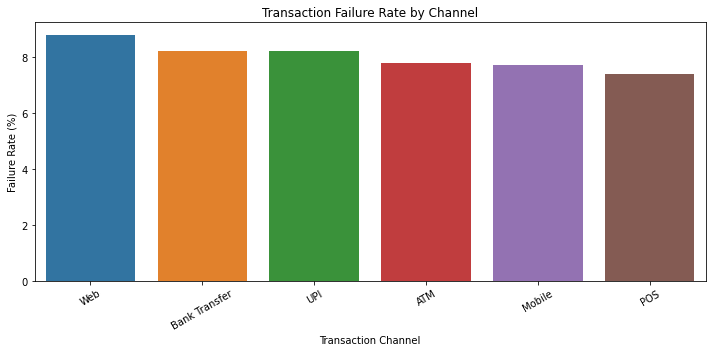

In [9]:
# Calculate channel-wise transaction metrics
channel_analysis = (
    df_transactions_clean
    .groupby("channel")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=(
            "status",
            lambda s: (s == "Failed").sum()
        )
    )
    .reset_index()
)

# Calculate failure percentage
channel_analysis["failure_rate_pct"] = (
    channel_analysis["failed_transactions"]
    / channel_analysis["total_transactions"]
    * 100
).round(2)

# Sort from highest to lowest failure rate
channel_analysis = channel_analysis.sort_values(
    "failure_rate_pct",
    ascending=False
)

# Display the results
display(channel_analysis)

# Create the chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=channel_analysis,
    x="channel",
    y="failure_rate_pct"
)

plt.title("Transaction Failure Rate by Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# Load the remaining project tables from MySQL
df_accounts = pd.read_sql(
    "SELECT * FROM accounts", engine
)

df_kyc = pd.read_sql(
    "SELECT * FROM kyc_records", engine
)

df_risk_factors = pd.read_sql(
    "SELECT * FROM risk_factors", engine
)

df_alerts = pd.read_sql(
    "SELECT * FROM alerts", engine
)

# Verify the loaded data
datasets = {
    "Customers": df_customers,
    "Accounts": df_accounts,
    "Transactions": df_transactions_clean,
    "KYC Records": df_kyc,
    "Risk Factors": df_risk_factors,
    "Alerts": df_alerts
}

for name, df in datasets.items():
    print(
        f"{name}: {df.shape[0]:,} rows, "
        f"{df.shape[1]} columns"
    )

Customers: 1,001 rows, 10 columns
Accounts: 1,186 rows, 6 columns
Transactions: 15,143 rows, 11 columns
KYC Records: 1,000 rows, 7 columns
Risk Factors: 1,000 rows, 7 columns
Alerts: 1,159 rows, 8 columns


In [11]:
# Audit all six datasets
for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(f"DATA QUALITY REPORT: {name}")
    print(f"{'=' * 45}")

    print("Rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())

    print("\nMissing values:")
    print(df.isnull().sum().to_string())

    # Check duplicate IDs for each table
    id_columns = [
        col for col in df.columns
        if col.endswith("_id")
    ]

    for col in id_columns:
        print(
            f"Duplicate {col}:",
            df[col].duplicated().sum()
        )


DATA QUALITY REPORT: Customers
Rows: 1001
Duplicate rows: 0

Missing values:
customer_id       0
first_name        0
last_name         0
gender            0
dob               0
country           0
state             0
city              0
occupation        0
customer_since    0
Duplicate customer_id: 0

DATA QUALITY REPORT: Accounts
Rows: 1186
Duplicate rows: 0

Missing values:
account_id        0
customer_id       0
account_type      0
account_status    0
opening_date      0
annual_income     0
Duplicate account_id: 0
Duplicate customer_id: 186

DATA QUALITY REPORT: Transactions
Rows: 15143
Duplicate rows: 0

Missing values:
transaction_id       0
account_id           0
transaction_date     0
transaction_type     0
channel              0
amount               0
currency             0
merchant_category    0
country              0
city                 0
status               0
Duplicate transaction_id: 0
Duplicate account_id: 13957

DATA QUALITY REPORT: KYC Records
Rows: 1000
Duplicate row

In [12]:
# Check whether foreign-key references exist

checks = {
    "Accounts -> Customers": (
        df_accounts["customer_id"],
        df_customers["customer_id"]
    ),
    "Transactions -> Accounts": (
        df_transactions_clean["account_id"],
        df_accounts["account_id"]
    ),
    "KYC -> Customers": (
        df_kyc["customer_id"],
        df_customers["customer_id"]
    ),
    "Risk Factors -> Customers": (
        df_risk_factors["customer_id"],
        df_customers["customer_id"]
    ),
    "Alerts -> Transactions": (
        df_alerts["transaction_id"],
        df_transactions_clean["transaction_id"]
    ),
    "Alerts -> Customers": (
        df_alerts["customer_id"],
        df_customers["customer_id"]
    )
}

for relationship, (child_ids, parent_ids) in checks.items():
    missing = (~child_ids.isin(parent_ids)).sum()

    print(
        f"{relationship}: "
        f"{missing} orphan records"
    )

Accounts -> Customers: 0 orphan records
Transactions -> Accounts: 0 orphan records
KYC -> Customers: 0 orphan records
Risk Factors -> Customers: 0 orphan records
Alerts -> Transactions: 0 orphan records
Alerts -> Customers: 0 orphan records


In [13]:
# Step 1: Aggregate transactions at account level
account_summary = (
    df_transactions_clean
    .groupby("account_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        max_transaction=("amount", "max"),
        failed_transactions=(
            "status",
            lambda s: (s == "Failed").sum()
        ),
        high_value_transactions=(
            "amount",
            lambda s: (s >= 100000).sum()
        )
    )
    .reset_index()
)

# Step 2: Attach account summaries to accounts
account_customer = df_accounts.merge(
    account_summary,
    on="account_id",
    how="left",
    validate="one_to_one"
)

# Step 3: Aggregate accounts at customer level
customer_transaction_summary = (
    account_customer
    .groupby("customer_id")
    .agg(
        total_accounts=("account_id", "nunique"),
        total_transactions=("total_transactions", "sum"),
        total_transaction_amount=("total_amount", "sum"),
        average_transaction_amount=("average_amount", "mean"),
        highest_transaction=("max_transaction", "max"),
        failed_transactions=("failed_transactions", "sum"),
        high_value_transactions=("high_value_transactions", "sum")
    )
    .reset_index()
)

# Step 4: Combine customer profile and risk factors
df_customer_risk = (
    df_customers
    .merge(
        df_risk_factors,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        customer_transaction_summary,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
)

print("Customer risk dataset created!")
print("Shape:", df_customer_risk.shape)

df_customer_risk.head()

Customer risk dataset created!
Shape: (1001, 23)


,customer_id,first_name,last_name,gender,dob,country,state,city,occupation,customer_since,...,transaction_risk,kyc_risk,previous_alerts,total_accounts,total_transactions,total_transaction_amount,average_transaction_amount,highest_transaction,failed_transactions,high_value_transactions
0,C10000,Vikram,Iyer,Male,1985-04-15,UK,Maharashtra,Mumbai,Business Owner,2022-01-31,...,Medium,Low,0.0,1.0,18.0,96727.17,5373.731667,20772.47,3.0,0.0
1,C10001,Riya,Verma,Male,1988-01-25,India,Bihar,Patna,Business Owner,2025-08-15,...,High,Low,1.0,1.0,11.0,64691.03,5881.002727,17008.31,1.0,0.0
2,C10002,Isha,Sharma,Other,1994-08-08,UAE,Tamil Nadu,Chennai,Consultant,2024-08-31,...,High,High,3.0,1.0,12.0,433146.09,36095.507500,380496.00,0.0,1.0
3,C10003,Saurabh,Malhotra,Female,2002-12-26,UK,Bihar,Patna,IT Professional,2021-06-21,...,Low,Low,3.0,2.0,31.0,207812.63,6753.860750,40878.35,4.0,0.0
4,C10004,Pooja,Patel,Male,2003-02-15,India,Delhi,New Delhi,Teacher,2022-10-25,...,Low,Low,2.0,1.0,17.0,81301.97,4782.468824,31216.63,1.0,0.0


In [14]:
# Check customer-level dataset
print("Dataset shape:", df_customer_risk.shape)
print("Unique customers:", df_customer_risk["customer_id"].nunique())

# Check customers with no transaction history
print(
    "Customers without transactions:",
    df_customer_risk["total_transactions"].isna().sum()
)

# Fill missing transaction metrics with zero
transaction_metrics = [
    "total_accounts",
    "total_transactions",
    "total_transaction_amount",
    "failed_transactions",
    "high_value_transactions"
]

df_customer_risk[transaction_metrics] = (
    df_customer_risk[transaction_metrics].fillna(0)
)

# Calculate the exact customer-level average
df_customer_risk["average_transaction_amount"] = (
    df_customer_risk["total_transaction_amount"]
    .div(
        df_customer_risk["total_transactions"].replace(0, np.nan)
    )
    .fillna(0)
    .round(2)
)

print("\nCorrected dataset shape:", df_customer_risk.shape)

print("\nCustomer transaction summary:")
display(
    df_customer_risk[
        [
            "customer_id",
            "total_accounts",
            "total_transactions",
            "total_transaction_amount",
            "average_transaction_amount",
            "failed_transactions",
            "high_value_transactions"
        ]
    ].head(10)
)

Dataset shape: (1001, 23)
Unique customers: 1001
Customers without transactions: 1

Corrected dataset shape: (1001, 23)

Customer transaction summary:


,customer_id,total_accounts,total_transactions,total_transaction_amount,average_transaction_amount,failed_transactions,high_value_transactions
0,C10000,1.0,18.0,96727.17,5373.73,3.0,0.0
1,C10001,1.0,11.0,64691.03,5881.00,1.0,0.0
2,C10002,1.0,12.0,433146.09,36095.51,0.0,1.0
3,C10003,2.0,31.0,207812.63,6703.63,4.0,0.0
4,C10004,1.0,17.0,81301.97,4782.47,1.0,0.0
5,C10005,1.0,15.0,511255.47,34083.70,0.0,1.0
6,C10006,1.0,11.0,143202.09,13018.37,1.0,0.0
7,C10007,1.0,11.0,93067.29,8460.66,1.0,0.0
8,C10008,2.0,29.0,987249.36,34043.08,5.0,3.0
9,C10009,1.0,11.0,58561.67,5323.79,3.0,0.0


In [15]:
# Inspect the categories used in risk factors
risk_columns = [
    "occupation_risk",
    "geography_risk",
    "transaction_risk",
    "kyc_risk"
]

for col in risk_columns:
    print(f"\n{col}:")
    print(df_customer_risk[col].value_counts(dropna=False))

print("\nPrevious alerts distribution:")
print(
    df_customer_risk["previous_alerts"]
    .describe()
)

print("\nTransaction behaviour:")
print(
    df_customer_risk[
        [
            "total_transactions",
            "failed_transactions",
            "high_value_transactions",
            "highest_transaction"
        ]
    ].describe().round(2)
)


occupation_risk:
Low       484
Medium    262
High      254
NaN         1
Name: occupation_risk, dtype: int64

geography_risk:
Low       506
High      248
Medium    246
NaN         1
Name: geography_risk, dtype: int64

transaction_risk:
Medium    488
High      276
Low       236
NaN         1
Name: transaction_risk, dtype: int64

kyc_risk:
Low       474
Medium    279
High      247
NaN         1
Name: kyc_risk, dtype: int64

Previous alerts distribution:
count    1000.00000
mean        2.57600
std         1.68614
min         0.00000
25%         1.00000
50%         3.00000
75%         4.00000
max         5.00000
Name: previous_alerts, dtype: float64

Transaction behaviour:
       total_transactions  failed_transactions  high_value_transactions  \
count             1001.00              1001.00                  1001.00   
mean                15.13                 1.21                     0.04   
std                  6.43                 1.23                     0.25   
min                  

In [16]:
# STEP 1: Define illustrative risk weights
risk_weights = {
    "occupation_risk": 15,
    "geography_risk": 20,
    "transaction_risk": 20,
    "kyc_risk": 20
}

category_scores = {
    "Low": 0.0,
    "Medium": 0.5,
    "High": 1.0
}

# STEP 2: Flag missing risk categories
risk_cols = list(risk_weights.keys())

df_customer_risk["missing_risk_data"] = (
    df_customer_risk[risk_cols]
    .isna()
    .any(axis=1)
)

# STEP 3: Calculate points for each risk category
for col, weight in risk_weights.items():

    mapped_score = (
        df_customer_risk[col]
        .map(category_scores)
        .fillna(0.5)  # Neutral score for missing category
    )

    df_customer_risk[f"{col}_points"] = (
        mapped_score * weight
    )

# STEP 4: Score previous alerts (maximum 10 points)
previous_alerts = (
    df_customer_risk["previous_alerts"]
    .fillna(0)
    .clip(lower=0, upper=5)
)

df_customer_risk["previous_alerts_points"] = (
    previous_alerts / 5 * 10
)

# STEP 5: Score transaction behaviour (maximum 15 points)
# High-value transactions: maximum 8 points
high_value_count = (
    df_customer_risk["high_value_transactions"]
    .fillna(0)
    .clip(lower=0, upper=3)
)

df_customer_risk["high_value_points"] = (
    high_value_count / 3 * 8
)

# Failed transaction rate: maximum 7 points
total_txn = df_customer_risk["total_transactions"].fillna(0)
failed_txn = df_customer_risk["failed_transactions"].fillna(0)

failure_rate = (
    failed_txn.div(total_txn.replace(0, np.nan))
    .fillna(0)
    .clip(lower=0, upper=0.20)
)

df_customer_risk["failure_rate"] = failure_rate

df_customer_risk["failure_rate_points"] = (
    failure_rate / 0.20 * 7
)

df_customer_risk["behaviour_points"] = (
    df_customer_risk["high_value_points"]
    + df_customer_risk["failure_rate_points"]
)

# STEP 6: Calculate final score
point_columns = [
    "occupation_risk_points",
    "geography_risk_points",
    "transaction_risk_points",
    "kyc_risk_points",
    "previous_alerts_points",
    "behaviour_points"
]

df_customer_risk["risk_score"] = (
    df_customer_risk[point_columns]
    .sum(axis=1)
    .clip(0, 100)
    .round(2)
)

# STEP 7: Assign illustrative risk bands
df_customer_risk["risk_band"] = pd.cut(
    df_customer_risk["risk_score"],
    bins=[-0.01, 25, 50, 75, 100],
    labels=["Low", "Medium", "High", "Critical"]
)

print("Risk scoring engine created successfully!")
print("\nRisk band distribution:")
print(df_customer_risk["risk_band"].value_counts().sort_index())

print("\nMissing risk data flags:")
print(df_customer_risk["missing_risk_data"].value_counts())

display(
    df_customer_risk[
        [
            "customer_id",
            "risk_score",
            "risk_band",
            "missing_risk_data",
            "previous_alerts",
            "high_value_transactions",
            "failed_transactions"
        ]
    ].sort_values("risk_score", ascending=False).head(10)
)

Risk scoring engine created successfully!

Risk band distribution:
Low         199
Medium      562
High        229
Critical     11
Name: risk_band, dtype: int64

Missing risk data flags:
False    1000
True        1
Name: missing_risk_data, dtype: int64


,customer_id,risk_score,risk_band,missing_risk_data,previous_alerts,high_value_transactions,failed_transactions
130,C10130,91.36,Critical,False,5.0,0.0,2.0
213,C10213,86.50,Critical,False,4.0,0.0,2.0
394,C10394,84.50,Critical,False,3.0,0.0,1.0
808,C10808,82.00,Critical,False,5.0,0.0,2.0
951,C10951,81.88,Critical,False,5.0,0.0,1.0
473,C10473,79.83,Critical,False,5.0,0.0,1.0
606,C10606,77.50,Critical,False,5.0,0.0,0.0
641,C10641,76.85,Critical,False,3.0,1.0,1.0
245,C10245,76.68,Critical,False,3.0,0.0,1.0
226,C10226,76.18,Critical,False,4.0,0.0,1.0


In [17]:
# Validate the risk scoring engine

print("Total customer records:", len(df_customer_risk))

print(
    "Unique customer IDs:",
    df_customer_risk["customer_id"].nunique()
)

print(
    "Minimum risk score:",
    df_customer_risk["risk_score"].min()
)

print(
    "Maximum risk score:",
    df_customer_risk["risk_score"].max()
)

print(
    "Scores outside 0-100:",
    (
        (df_customer_risk["risk_score"] < 0)
        | (df_customer_risk["risk_score"] > 100)
    ).sum()
)

print(
    "Missing risk scores:",
    df_customer_risk["risk_score"].isna().sum()
)

# Check whether risk bands match their scores
expected_band = pd.cut(
    df_customer_risk["risk_score"],
    bins=[-0.01, 25, 50, 75, 100],
    labels=["Low", "Medium", "High", "Critical"]
)

band_mismatches = (
    df_customer_risk["risk_band"].astype(str)
    != expected_band.astype(str)
).sum()

print("Risk band mismatches:", band_mismatches)

print("\nRisk score summary:")
display(
    df_customer_risk["risk_score"]
    .describe()
    .round(2)
)

Total customer records: 1001
Unique customer IDs: 1001
Minimum risk score: 0.0
Maximum risk score: 91.36
Scores outside 0-100: 0
Missing risk scores: 0
Risk band mismatches: 0

Risk score summary:


count    1001.00
mean       39.24
std        15.59
min         0.00
25%        28.00
50%        38.84
75%        49.83
max        91.36
Name: risk_score, dtype: float64

In [18]:
import os

# Create a dedicated output folder
output_folder = os.path.join(
    os.getcwd(),
    "FinSecure_Output"
)

os.makedirs(output_folder, exist_ok=True)

# Export the customer-level risk dataset
output_file = os.path.join(
    output_folder,
    "customer_risk_scoring.csv"
)

df_customer_risk.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Export successful!")
print("File location:", output_file)
print("Rows exported:", len(df_customer_risk))
print("Columns exported:", len(df_customer_risk.columns))

Export successful!
File location: C:\Users\91980\FinSecure_Output\customer_risk_scoring.csv
Rows exported: 1001
Columns exported: 35


In [19]:
# Read the exported CSV back into Python
df_exported = pd.read_csv(
    output_file,
    encoding="utf-8-sig"
)

print("Exported file shape:", df_exported.shape)

print(
    "Unique customers:",
    df_exported["customer_id"].nunique()
)

print(
    "\nRisk band distribution:"
)

print(
    df_exported["risk_band"].value_counts(
        dropna=False
    )
)

print(
    "\nMissing risk scores:",
    df_exported["risk_score"].isna().sum()
)

print("\nSample exported records:")

display(
    df_exported[
        [
            "customer_id",
            "risk_score",
            "risk_band",
            "missing_risk_data",
            "total_transactions",
            "failed_transactions"
        ]
    ].head()
)

Exported file shape: (1001, 35)
Unique customers: 1001

Risk band distribution:
Medium      562
High        229
Low         199
Critical     11
Name: risk_band, dtype: int64

Missing risk scores: 0

Sample exported records:


,customer_id,risk_score,risk_band,missing_risk_data,total_transactions,failed_transactions
0,C10000,15.83,Low,False,18.0,3.0
1,C10001,32.68,Medium,False,11.0,1.0
2,C10002,58.67,High,False,12.0,0.0
3,C10003,10.52,Low,False,31.0,4.0
4,C10004,33.56,Medium,False,17.0,1.0
